# Experiment 9: News Article Multiclass Classification
## NLP Mini Project — Extended EDA and Model Comparison

**Dataset:** News Classification Dataset 2026 | NLP & TC  
**Kaggle:** `mmumairkhattak/news-classification-dataset-2026-nlp-and-tc`

### Aim
To develop a multiclass NLP system for news classification, perform detailed exploratory data analysis, and compare multiple machine-learning classifiers using common evaluation metrics.

### Pipeline
Dataset → Extended EDA → Text Cleaning → TF-IDF → Train/Test Split → 7 Model Study → Evaluation → Comparison → Error Analysis → Prediction


## 1. Install Required Package


In [1]:
!pip -q install kagglehub

## 2. Import Libraries


In [2]:
import os
import re
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression, SGDClassifier, PassiveAggressiveClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import RidgeClassifier
from collections import Counter
import time
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Download Dataset from Kaggle


In [3]:
path = kagglehub.dataset_download(
    "mmumairkhattak/news-classification-dataset-2026-nlp-and-tc"
)
print("Dataset downloaded to:", path)

Using Colab cache for faster access to the 'news-classification-dataset-2026-nlp-and-tc' dataset.
Dataset downloaded to: /kaggle/input/news-classification-dataset-2026-nlp-and-tc


## 4. Inspect Dataset Files


In [4]:
all_files = []
for root, dirs, files in os.walk(path):
    for file in files:
        all_files.append(os.path.join(root, file))

print("Files available:")
for file in all_files:
    print(file)

Files available:
/kaggle/input/news-classification-dataset-2026-nlp-and-tc/data_dictionary.csv
/kaggle/input/news-classification-dataset-2026-nlp-and-tc/news_classification_dataset.csv
/kaggle/input/news-classification-dataset-2026-nlp-and-tc/news_classification_notebook.ipynb


## 5. Load Dataset


In [5]:
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
if not csv_files:
    raise FileNotFoundError("No CSV file found in the downloaded dataset.")

print("CSV files:", csv_files)
df = pd.read_csv(csv_files[0])

print("\nDataset Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

CSV files: ['/kaggle/input/news-classification-dataset-2026-nlp-and-tc/data_dictionary.csv', '/kaggle/input/news-classification-dataset-2026-nlp-and-tc/news_classification_dataset.csv']

Dataset Shape: (15, 2)
Columns: ['Column', 'Description']


,Column,Description
0,Article_ID,Unique identifier assigned to each news article
1,Title,Headline or title of the news article
2,Article_Text,Main body text of the news article
3,Full_Text,Combined title and article text used for NLP m...
4,Category,Target news category label for classification


## 6. Dataset Information and EDA


In [6]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
print("\nData Types:\n", df.dtypes)

Dataset Shape: (15, 2)

Column Names: ['Column', 'Description']

Missing Values:
 Column         0
Description    0
dtype: int64

Duplicate Rows: 0

Data Types:
 Column         object
Description    object
dtype: object


## 7. Detect Text and Target Columns
The notebook tries common column names automatically. If your dataset uses unusual names, set `text_col` and `target_col` manually in this cell.


In [7]:
text_candidates = ['text', 'content', 'article', 'description', 'headline', 'title', 'news', 'body']
target_candidates = ['category', 'label', 'class', 'topic', 'target', 'type']

lower_map = {str(c).lower(): c for c in df.columns}
text_col = next((lower_map[x] for x in text_candidates if x in lower_map), None)
target_col = next((lower_map[x] for x in target_candidates if x in lower_map), None)

# Fallback heuristics
if text_col is None:
    object_cols = [c for c in df.columns if df[c].dtype == 'object']
    if object_cols:
        text_col = max(object_cols, key=lambda c: df[c].astype(str).str.len().mean())

if target_col is None:
    candidates = [c for c in df.columns if c != text_col and df[c].nunique() > 1]
    small_cardinality = [c for c in candidates if df[c].nunique() <= 100]
    if small_cardinality:
        target_col = min(small_cardinality, key=lambda c: df[c].nunique())

print("Detected text column:", text_col)
print("Detected target column:", target_col)

# If these are incorrect, uncomment and edit:
# text_col = "YOUR_TEXT_COLUMN"
# target_col = "YOUR_LABEL_COLUMN"

if text_col is None or target_col is None:
    raise ValueError("Could not detect columns. Set text_col and target_col manually above.")

Detected text column: Description
Detected target column: Column


## 8. Examine News Categories


In [8]:
print("Text column:", text_col)
print("Target column:", target_col)
print("\nNumber of Classes:", df[target_col].nunique())
print("\nCategories:", df[target_col].dropna().unique())
print("\nCategory Distribution:\n", df[target_col].value_counts())

Text column: Description
Target column: Column

Number of Classes: 15

Categories: ['Article_ID' 'Title' 'Article_Text' 'Full_Text' 'Category' 'Source'
 'Author' 'Region' 'Published_Date' 'Keywords' 'Title_Length'
 'Article_Length' 'Word_Count' 'Reading_Difficulty' 'Language']

Category Distribution:
 Column
Article_ID            1
Title                 1
Article_Text          1
Full_Text             1
Category              1
Source                1
Author                1
Region                1
Published_Date        1
Keywords              1
Title_Length          1
Article_Length        1
Word_Count            1
Reading_Difficulty    1
Language              1
Name: count, dtype: int64


## 9. Category Distribution


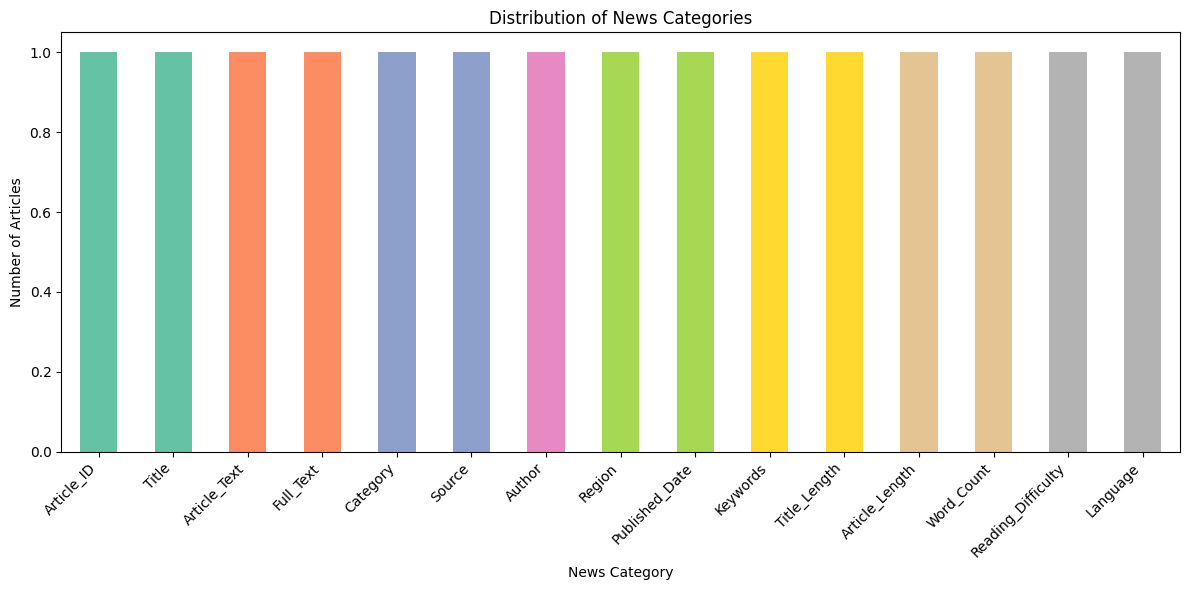

In [9]:
category_counts = df[target_col].value_counts()
plt.figure(figsize=(12, 6))
colors = plt.cm.Set2(np.linspace(0, 1, len(category_counts)))
category_counts.plot(kind="bar", color=colors)
plt.title("Distribution of News Categories")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 10. Clean Dataset


In [10]:
# Identify the actual dataset CSV file and load it correctly
dataset_csv = next((f for f in csv_files if "news_classification_dataset.csv" in f), csv_files[0])
df = pd.read_csv(dataset_csv)

# Redetect columns since we loaded the new dataframe
text_col = 'Full_Text' if 'Full_Text' in df.columns else ('Article_Text' if 'Article_Text' in df.columns else 'Description')
target_col = 'Category' if 'Category' in df.columns else 'Column'

data = df[[text_col, target_col, 'Article_ID']].copy()
data = data.dropna()
data[text_col] = data[text_col].astype(str)
data[target_col] = data[target_col].astype(str)
# Drop duplicates based on Article_ID instead of Title to keep the dataset size intact
data = data.drop_duplicates(subset=['Article_ID'])

print("Shape after removing missing values and duplicates:", data.shape)
display(data.head())

Shape after removing missing values and duplicates: (30000, 3)


,Full_Text,Category,Article_ID
0,New AI platform launched for enterprise automa...,Technology,NEWS000001
1,Film receives strong reviews after premiere in...,Entertainment,NEWS000002
2,Global markets rise as investor confidence imp...,Business,NEWS000003
3,New AI platform launched for enterprise automa...,Technology,NEWS000004
4,Universities expand online learning programs. ...,Education,NEWS000005


## 11. Text Preprocessing


In [11]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'\d+', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

data["clean_text"] = data[text_col].apply(clean_text)
data = data[data["clean_text"].str.len() > 0]

display(data[[text_col, "clean_text", target_col]].head())

,Full_Text,clean_text,Category
0,New AI platform launched for enterprise automa...,new ai platform launched for enterprise automa...,Technology
1,Film receives strong reviews after premiere in...,film receives strong reviews after premiere in...,Entertainment
2,Global markets rise as investor confidence imp...,global markets rise as investor confidence imp...,Business
3,New AI platform launched for enterprise automa...,new ai platform launched for enterprise automa...,Technology
4,Universities expand online learning programs. ...,universities expand online learning programs e...,Education


## Extended Exploratory Data Analysis
The following cells study article length, class balance, vocabulary, and common words before model training.


In [12]:
# Basic text-length features for EDA
data["char_count"] = data["clean_text"].str.len()
data["word_count"] = data["clean_text"].str.split().str.len()

print("Text-length statistics:")
display(data[["char_count", "word_count"]].describe().round(2))

print("\nClass balance (%):")
class_balance = (data[target_col].value_counts(normalize=True) * 100).round(2)
display(class_balance.rename("Percentage").to_frame())

Text-length statistics:


,char_count,word_count
count,30000.00,30000.00
mean,129.99,16.99
std,10.35,1.54
min,112.00,15.00
25%,121.00,15.00
50%,132.00,17.00
75%,141.00,18.00
max,144.00,20.00



Class balance (%):


,Percentage
Category,
Business,12.71
Health,12.68
Entertainment,12.54
Education,12.52
Politics,12.52
Technology,12.45
Sports,12.30
Science,12.29


### EDA 1 — Article Word-Count Distribution


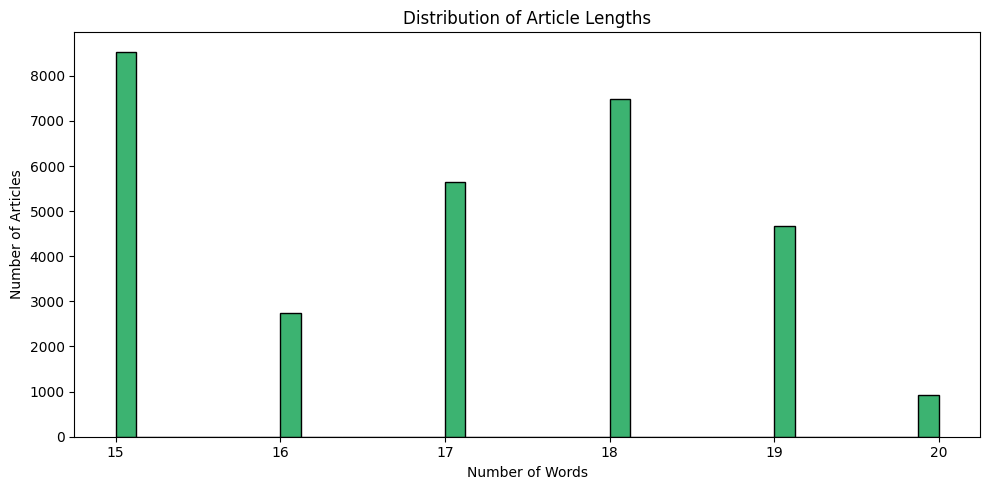

In [13]:
plt.figure(figsize=(10, 5))
plt.hist(data["word_count"], bins=40, color="mediumseagreen", edgecolor="black")
plt.title("Distribution of Article Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.show()

### EDA 2 — Average Article Length by Category


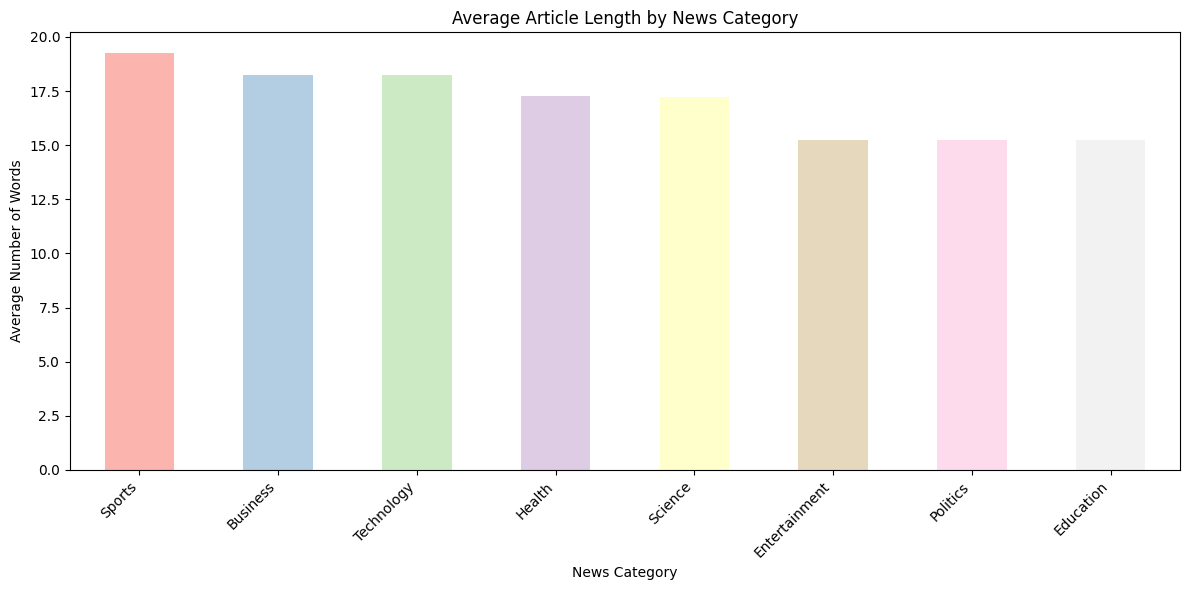

,Average Word Count
Category,
Sports,19.25
Business,18.26
Technology,18.25
Health,17.25
Science,17.24
Entertainment,15.26
Politics,15.24
Education,15.23


In [14]:
avg_len = data.groupby(target_col)["word_count"].mean().sort_values(ascending=False)
plt.figure(figsize=(12, 6))
colors = plt.cm.Pastel1(np.linspace(0, 1, len(avg_len)))
avg_len.plot(kind="bar", color=colors)
plt.title("Average Article Length by News Category")
plt.xlabel("News Category")
plt.ylabel("Average Number of Words")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
display(avg_len.round(2).rename("Average Word Count").to_frame())

### EDA 3 — Most Frequent Words in the Corpus


,Word,Frequency
0,new,14932
1,introduced,11246
2,markets,7628
3,online,7512
4,learning,7512
5,policy,7512
6,platform,7468
7,strong,7451
8,team,7380
9,global,3814


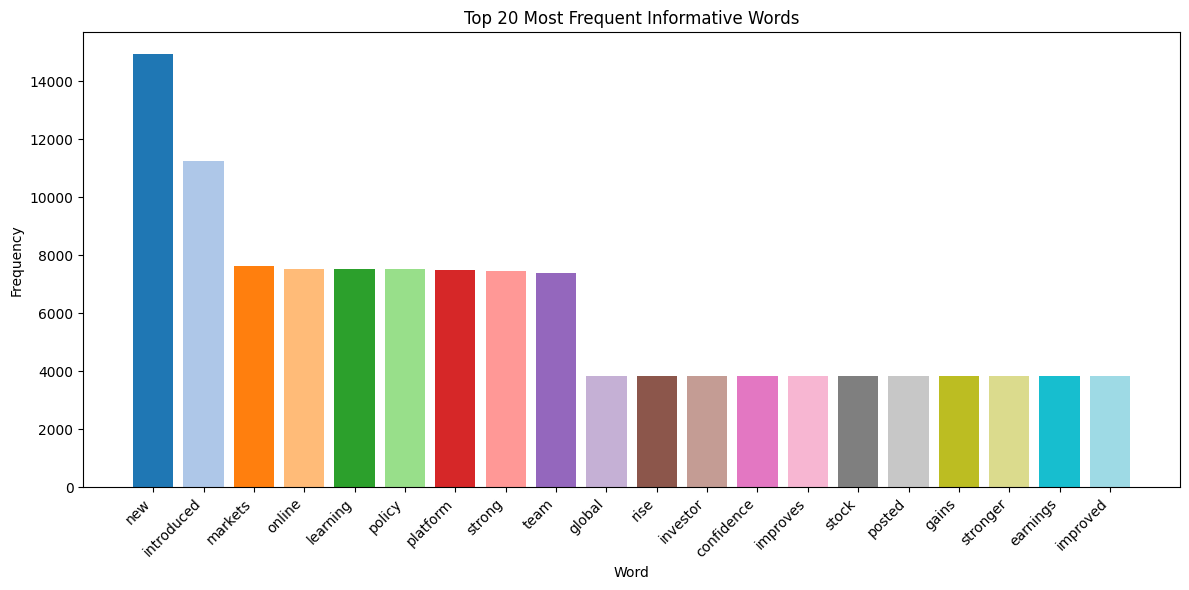

In [15]:
all_words = " ".join(data["clean_text"]).split()
# Remove common English stop words using sklearn's built-in list
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
filtered_words = [w for w in all_words if w not in ENGLISH_STOP_WORDS and len(w) > 2]
top_words = Counter(filtered_words).most_common(20)
top_words_df = pd.DataFrame(top_words, columns=["Word", "Frequency"])
display(top_words_df)

plt.figure(figsize=(12, 6))
colors = plt.cm.tab20(np.linspace(0, 1, len(top_words_df)))
plt.bar(top_words_df["Word"], top_words_df["Frequency"], color=colors)
plt.title("Top 20 Most Frequent Informative Words")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### EDA 4 — Vocabulary Size and Unique-Word Statistics


In [16]:
vocabulary = set(filtered_words)
print("Total word tokens after stop-word filtering:", len(filtered_words))
print("Unique informative words:", len(vocabulary))
print("Lexical diversity (unique / total):", round(len(vocabulary) / max(len(filtered_words), 1), 4))

category_text_stats = data.groupby(target_col).agg(
    Articles=(target_col, "size"),
    Avg_Words=("word_count", "mean"),
    Median_Words=("word_count", "median"),
    Min_Words=("word_count", "min"),
    Max_Words=("word_count", "max")
).round(2)
display(category_text_stats)

Total word tokens after stop-word filtering: 405158
Unique informative words: 96
Lexical diversity (unique / total): 0.0002


,Articles,Avg_Words,Median_Words,Min_Words,Max_Words
Category,,,,,
Business,3814,18.26,18.0,18,19
Education,3756,15.23,15.0,15,16
Entertainment,3761,15.26,15.0,15,16
Health,3803,17.25,17.0,17,18
Politics,3756,15.24,15.0,15,16
Science,3686,17.24,17.0,17,18
Sports,3690,19.25,19.0,19,20
Technology,3734,18.25,18.0,18,19


## 12. Original vs Cleaned Example


In [17]:
print("ORIGINAL NEWS:\n", data[text_col].iloc[0])
print("\n" + "-"*60)
print("CLEANED NEWS:\n", data["clean_text"].iloc[0])
print("\n" + "-"*60)
print("CATEGORY:", data[target_col].iloc[0])

ORIGINAL NEWS:
 New AI platform launched for enterprise automation. A technology company introduced an artificial intelligence platform for business workflows.

------------------------------------------------------------
CLEANED NEWS:
 new ai platform launched for enterprise automation a technology company introduced an artificial intelligence platform for business workflows

------------------------------------------------------------
CATEGORY: Technology


## 13. Define Features and Target


In [18]:
X = data["clean_text"]
y = data[target_col]

print("Number of articles:", len(X))
print("Number of categories:", y.nunique())
print("Categories:", sorted(y.unique()))

Number of articles: 30000
Number of categories: 8
Categories: ['Business', 'Education', 'Entertainment', 'Health', 'Politics', 'Science', 'Sports', 'Technology']


## 14. Train-Test Split (80:20)


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 24000
Testing samples: 6000


## 15. TF-IDF Feature Extraction
Uses unigrams and bigrams to represent news text numerically.


In [20]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (24000, 198)
Testing TF-IDF shape: (6000, 198)


## 16. Train and Study Seven Classification Models
All models use the same TF-IDF features and train/test split for a fair comparison.

Models studied:
1. Multinomial Naive Bayes
2. Complement Naive Bayes
3. Logistic Regression
4. Linear SVM
5. Ridge Classifier
6. SGD Classifier
7. Passive-Aggressive Classifier


In [21]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Complement Naive Bayes": ComplementNB(),
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Linear SVM": LinearSVC(random_state=42),
    "Ridge Classifier": RidgeClassifier(),
    "SGD Classifier": SGDClassifier(loss="hinge", max_iter=2000, random_state=42),
    "Passive Aggressive": PassiveAggressiveClassifier(max_iter=2000, random_state=42)
}

predictions = {}
rows = []

for name, model in models.items():
    start_time = time.time()
    model.fit(X_train_tfidf, y_train)
    pred = model.predict(X_test_tfidf)
    elapsed = time.time() - start_time
    predictions[name] = pred

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_test, pred, average="weighted", zero_division=0),
        "Macro F1": f1_score(y_test, pred, average="macro", zero_division=0),
        "Training + Prediction Time (s)": elapsed
    })

results = pd.DataFrame(rows).sort_values("F1 Score", ascending=False).reset_index(drop=True)
display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,Macro F1,Training + Prediction Time (s)
0,Multinomial Naive Bayes,1.0,1.0,1.0,1.0,1.0,0.0672
1,Complement Naive Bayes,1.0,1.0,1.0,1.0,1.0,0.0650
2,Logistic Regression,1.0,1.0,1.0,1.0,1.0,0.2192
3,Linear SVM,1.0,1.0,1.0,1.0,1.0,2.1915
4,Ridge Classifier,1.0,1.0,1.0,1.0,1.0,0.1731
5,SGD Classifier,1.0,1.0,1.0,1.0,1.0,0.2279
6,Passive Aggressive,1.0,1.0,1.0,1.0,1.0,0.2368


## 17. Detailed Classification Reports


In [22]:
for name in results["Model"]:
    print("=" * 90)
    print(name)
    print("=" * 90)
    print(classification_report(y_test, predictions[name], zero_division=0))

Multinomial Naive Bayes
               precision    recall  f1-score   support

     Business       1.00      1.00      1.00       763
    Education       1.00      1.00      1.00       751
Entertainment       1.00      1.00      1.00       752
       Health       1.00      1.00      1.00       761
     Politics       1.00      1.00      1.00       751
      Science       1.00      1.00      1.00       737
       Sports       1.00      1.00      1.00       738
   Technology       1.00      1.00      1.00       747

     accuracy                           1.00      6000
    macro avg       1.00      1.00      1.00      6000
 weighted avg       1.00      1.00      1.00      6000

Complement Naive Bayes
               precision    recall  f1-score   support

     Business       1.00      1.00      1.00       763
    Education       1.00      1.00      1.00       751
Entertainment       1.00      1.00      1.00       752
       Health       1.00      1.00      1.00       761
     Politics 

## 20. Performance Comparison Graph


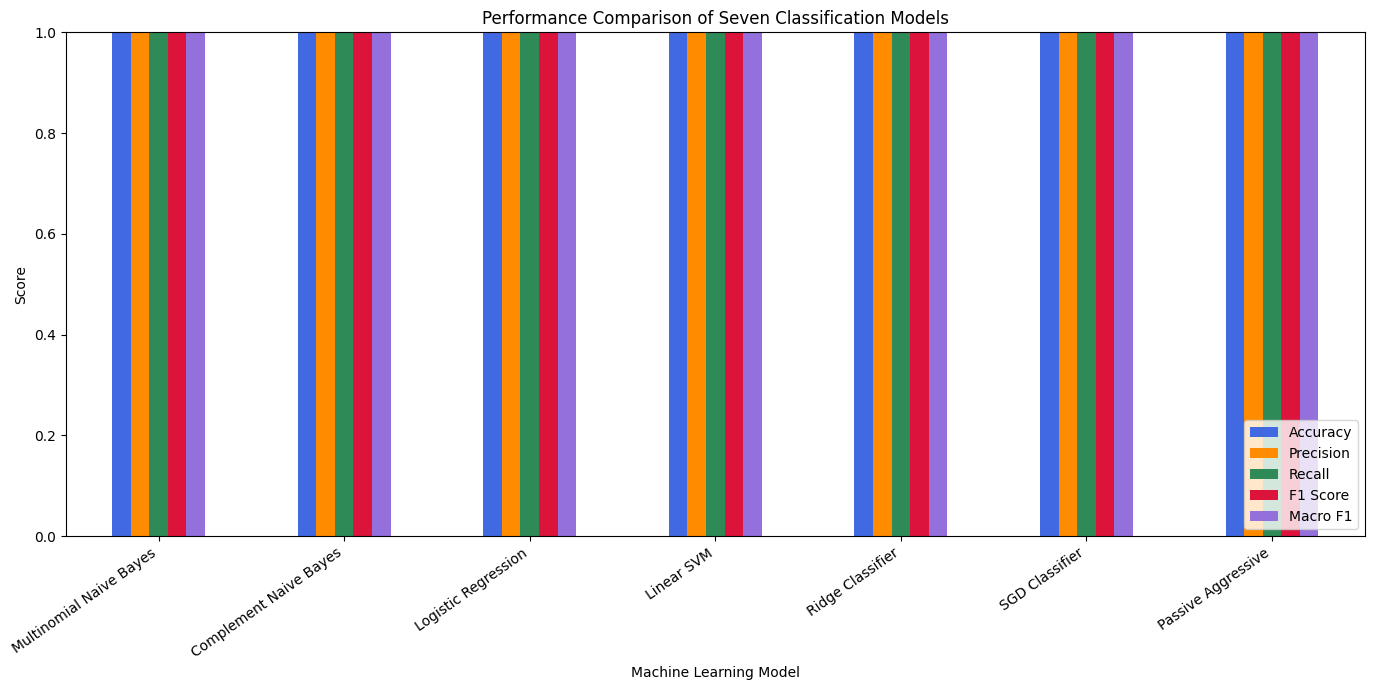

In [23]:
metric_colors = ["royalblue", "darkorange", "seagreen", "crimson", "mediumpurple"]
results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score", "Macro F1"]].plot(
    kind="bar", figsize=(14, 7), color=metric_colors
)
plt.title("Performance Comparison of Seven Classification Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 19. Computational Time Comparison
This helps study the trade-off between predictive performance and computational cost.


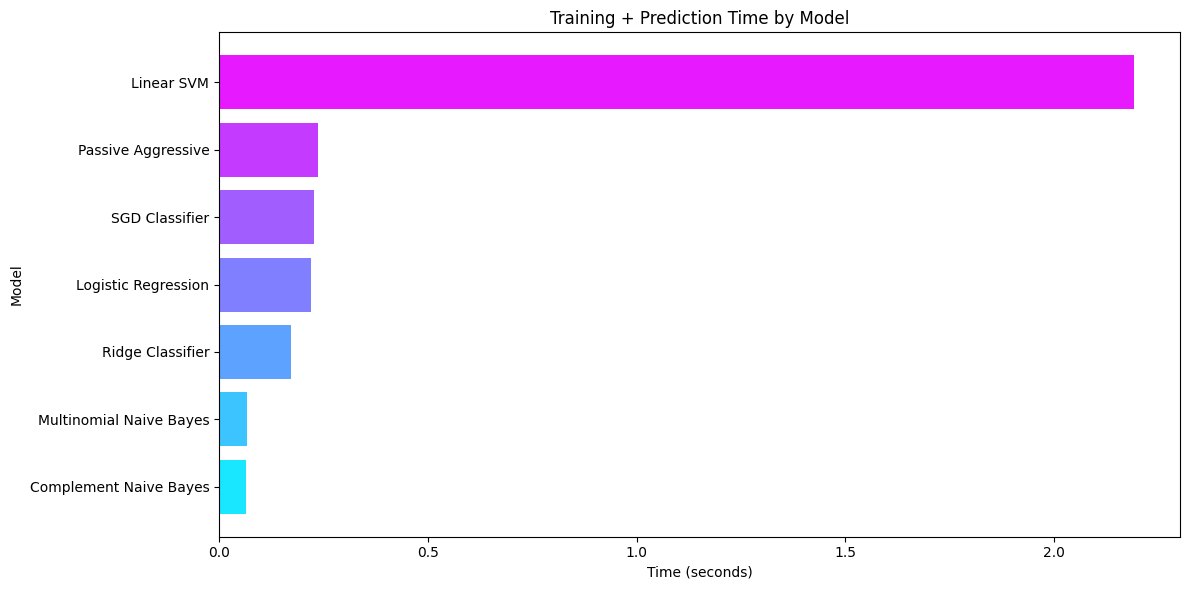

In [24]:
time_results = results.sort_values("Training + Prediction Time (s)")
plt.figure(figsize=(12, 6))
colors = plt.cm.cool(np.linspace(0.1, 0.9, len(time_results)))
plt.barh(time_results["Model"], time_results["Training + Prediction Time (s)"], color=colors)
plt.title("Training + Prediction Time by Model")
plt.xlabel("Time (seconds)")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

## 21. Select Best Model


In [25]:
best_index = results["F1 Score"].idxmax()
best_model_name = results.loc[best_index, "Model"]
best_model = models[best_model_name]

print("Best Performing Model:", best_model_name)
display(results.loc[[best_index]].round(4))

Best Performing Model: Multinomial Naive Bayes


,Model,Accuracy,Precision,Recall,F1 Score,Macro F1,Training + Prediction Time (s)
0,Multinomial Naive Bayes,1.0,1.0,1.0,1.0,1.0,0.0672


## 22. Confusion Matrix for the Best Model


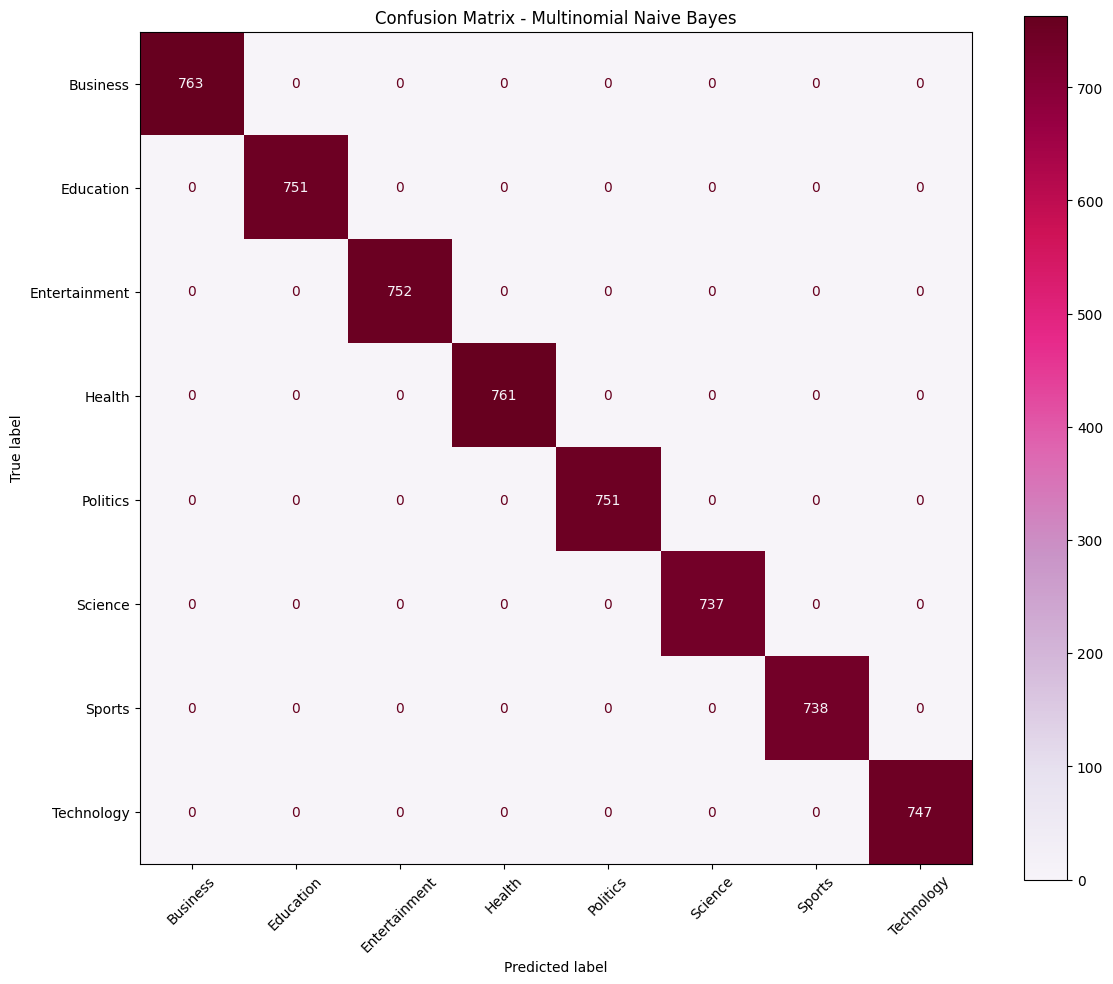

In [26]:
best_pred = predictions[best_model_name]
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, best_pred, labels=labels)

fig, ax = plt.subplots(figsize=(12, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, xticks_rotation=45, values_format="d", cmap="PuRd", colorbar=True)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

## 23. Prediction Function


In [27]:
def predict_news(news):
    cleaned = clean_text(news)
    vector = tfidf.transform([cleaned])
    return best_model.predict(vector)[0]

print("Prediction function ready.")

Prediction function ready.


## 24. Test with Sample News


In [28]:
samples = [
    "Apple announces new artificial intelligence features for its devices and software.",
    "The cricket team won the championship after a thrilling final match.",
    "Stock markets gained after investors reacted positively to quarterly financial results."
]

for news in samples:
    print("News:", news)
    print("Predicted Category:", predict_news(news))
    print("-"*70)

News: Apple announces new artificial intelligence features for its devices and software.
Predicted Category: Technology
----------------------------------------------------------------------
News: The cricket team won the championship after a thrilling final match.
Predicted Category: Sports
----------------------------------------------------------------------
News: Stock markets gained after investors reacted positively to quarterly financial results.
Predicted Category: Business
----------------------------------------------------------------------


## 25. Interactive Prediction — Demo Cell


In [29]:
user_news = input("Enter a news article or headline: ")
print("\nPredicted News Category:", predict_news(user_news))

Enter a news article or headline: Stock markets gained after investors reacted positively to quarterly financial results.

Predicted News Category: Business


# Algorithm
1. Download and load the news classification dataset.
2. Inspect columns, missing values, duplicates, and category frequencies.
3. Clean the text and derive article word/character counts.
4. Perform extended EDA: class balance, article-length distribution, category-wise length, frequent words, and vocabulary statistics.
5. Split the cleaned data into 80% training and 20% testing sets using stratification.
6. Convert text into TF-IDF unigram and bigram features.
7. Train seven classifiers: Multinomial NB, Complement NB, Logistic Regression, Linear SVM, Ridge, SGD, and Passive-Aggressive.
8. Compare accuracy, weighted precision, weighted recall, weighted F1, macro F1, and computation time.
9. Select the model with the highest weighted F1-score.
10. Study its confusion matrix and use it for unseen-news prediction.


# Result
The experiment now performs detailed exploratory analysis of the news corpus and compares seven machine-learning classifiers under the same TF-IDF representation and train/test split. The comparison table reports accuracy, weighted precision, weighted recall, weighted F1-score, macro F1-score, and execution time. Run all cells to obtain the dataset-specific numerical results; the notebook automatically selects the classifier with the highest weighted F1-score.


# Conclusion
Extended EDA provides a clearer understanding of class distribution, article lengths, vocabulary, and frequently occurring informative terms. Comparing probabilistic, linear, margin-based, and online-learning classifiers shows that model choice can affect both predictive quality and computation time. Using identical TF-IDF features and the same test set makes the comparison fair, while weighted and macro F1-scores provide complementary views of multiclass performance.


# Viva Questions
**1. What is multiclass classification?**  
Classification where an input can belong to one of more than two classes.

**2. Why is TF-IDF used?**  
It converts text into numerical features while emphasizing informative terms.

**3. Which algorithms are compared?**  
Multinomial Naive Bayes, Logistic Regression, and Linear SVM.

**4. Why is Linear SVM useful for NLP?**  
It performs well with high-dimensional sparse features such as TF-IDF.

**5. What is a confusion matrix?**  
It compares actual and predicted classes to show correct predictions and classification errors.

**6. Why use F1-score?**  
It combines precision and recall and is useful when class frequencies are uneven.

**7. What does `ngram_range=(1,2)` mean?**  
Both single words (unigrams) and consecutive two-word phrases (bigrams) are considered.

**8. Why use an 80:20 split?**  
80% is used to train the model and 20% is held out to evaluate performance on unseen data.

**9. What is overfitting?**  
When a model learns the training data too specifically and fails to generalize well to unseen data.

**10. What is the target variable?**  
The news category/class label.


# Additional Viva Questions for Extended Study
**11. Why compare weighted F1 and macro F1?**  
Weighted F1 accounts for class frequency, whereas macro F1 gives equal importance to every class.

**12. What is Complement Naive Bayes?**  
It is a Naive Bayes variant designed to improve performance on imbalanced text-classification datasets.

**13. What is Ridge Classifier?**  
It is a linear classifier based on ridge regression with L2 regularization.

**14. Why use SGDClassifier for text?**  
It efficiently learns linear models from high-dimensional sparse data and can scale to large datasets.

**15. What is Passive-Aggressive classification?**  
It is an online learning algorithm that remains unchanged for correctly classified examples and updates aggressively after mistakes.

**16. Why study computation time?**  
A slightly more accurate model may not always be preferable if it is substantially slower or more expensive to train.
